In [195]:
# project3 -- iris flower clustering

In [196]:
import pandas as pd
iris = pd.read_csv('/content/iris.csv')
print("Iris dataset loaded ")

Iris dataset loaded 


In [197]:
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species_number,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [198]:
iris.tail()

,sepal_length,sepal_width,petal_length,petal_width,species_number,species
145,6.7,3.0,5.2,2.3,2,virginica
146,6.3,2.5,5.0,1.9,2,virginica
147,6.5,3.0,5.2,2.0,2,virginica
148,6.2,3.4,5.4,2.3,2,virginica
149,5.9,3.0,5.1,1.8,2,virginica


In [199]:
iris.shape

(150, 6)

In [200]:
iris.columns.tolist()

['sepal_length',
 'sepal_width',
 'petal_length',
 'petal_width',
 'species_number',
 'species']

<function matplotlib.pyplot.tight_layout(*, pad: 'float' = 1.08, h_pad: 'float | None' = None, w_pad: 'float | None' = None, rect: 'tuple[float, float, float, float] | None' = None) -> 'None'>

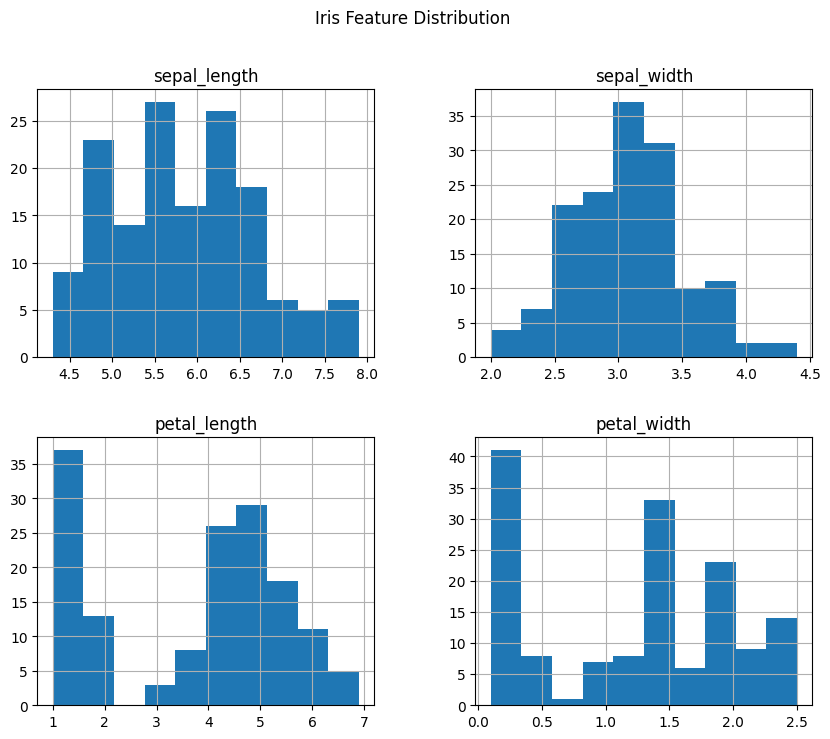

In [201]:
import matplotlib.pyplot as plt
iris_features.hist(
    bins=10,
    figsize=(10,8),
)
plt.suptitle("Iris Feature Distribution")
plt.tight_layout

In [202]:
iris.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   sepal_length    150 non-null    float64
 1   sepal_width     150 non-null    float64
 2   petal_length    150 non-null    float64
 3   petal_width     150 non-null    float64
 4   species_number  150 non-null    int64  
 5   species         150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [203]:
iris.describe()

,sepal_length,sepal_width,petal_length,petal_width,species_number
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [204]:
print("row",iris.shape[0])
print("column",iris.shape[1])

row 150
column 6


In [205]:
# Extract features from the current 'iris' DataFrame (after duplicates are dropped)
iris_features = iris[
   [
      "sepal_length",
      "sepal_width",
      "petal_length",
      "petal_width"
   ]
].copy()
iris_features.head()

,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [206]:
iris.isnull().sum()

,0
sepal_length,0
sepal_width,0
petal_length,0
petal_width,0
species_number,0
species,0


In [207]:
iris.duplicated().sum()

np.int64(1)

In [208]:
iris.drop_duplicates(inplace=True)

In [209]:
iris.duplicated().sum()


np.int64(0)

In [210]:
# Re-scale the updated features
from sklearn.preprocessing import StandardScaler
iris_scaler = StandardScaler().fit_transform(iris_features)

In [211]:
#use elbow method
from sklearn.cluster import KMeans
inertia_values = []
for K in range(1,11):
  kmeans = KMeans(n_clusters=K, max_iter=300, n_init=10, random_state=42)
  kmeans.fit(iris_scaler)
  inertia_values.append(kmeans.inertia_)

<function matplotlib.pyplot.show(close=None, block=None)>

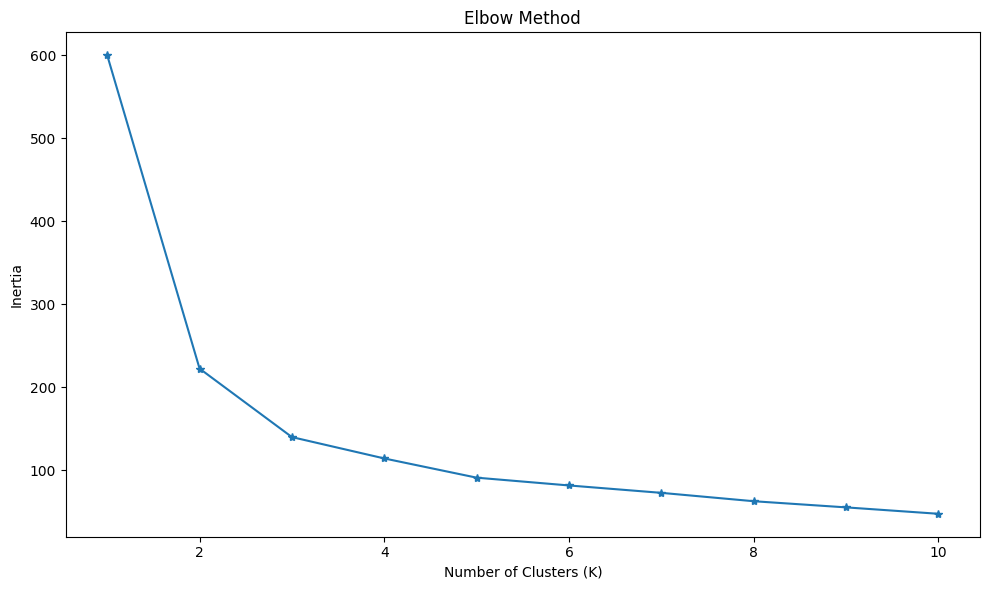

In [212]:
# plot elbow graph
plt.figure(figsize=(10,6))
plt.plot(range(1,11), inertia_values, marker='*')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.tight_layout()
plt.show

In [213]:
# train k-means with 3 clusters on 149 rows
kmeans_model = KMeans(
    n_clusters=3,
    max_iter=300,
    n_init=10,
    random_state=42,
)
iris_cluster = kmeans_model.fit_predict(
   iris_scaler
)

In [214]:
# 1. Extract features from the current cleaned 149-row 'iris' dataset
iris_features_clean = iris[["sepal_length", "sepal_width", "petal_length", "petal_width"]].copy()

# 2. Re-scale the clean features
from sklearn.preprocessing import StandardScaler
iris_scaler_clean = StandardScaler().fit_transform(iris_features_clean)

# 3. Fit K-Means on the 149-row scaled data
from sklearn.cluster import KMeans
kmeans_model = KMeans(n_clusters=3, max_iter=300, n_init=10, random_state=42)
iris_labels = kmeans_model.fit_predict(iris_scaler_clean)

# 4. Correctly assign the labels to a copy of the 149-row dataset
iris_clustered = iris.copy()
iris_clustered['cluster'] = iris_labels
iris_clustered['cluster'] = iris_clustered['cluster'].astype('category')

# Display the first few rows to confirm
iris_clustered # iris_clustere_head() kudutha 0-4 mattum

,sepal_length,sepal_width,petal_length,petal_width,species_number,species,cluster
0,5.1,3.5,1.4,0.2,0,setosa,1
1,4.9,3.0,1.4,0.2,0,setosa,1
2,4.7,3.2,1.3,0.2,0,setosa,1
3,4.6,3.1,1.5,0.2,0,setosa,1
4,5.0,3.6,1.4,0.2,0,setosa,1
...,...,...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2,virginica,2
146,6.3,2.5,5.0,1.9,2,virginica,0
147,6.5,3.0,5.2,2.0,2,virginica,2
148,6.2,3.4,5.4,2.3,2,virginica,2


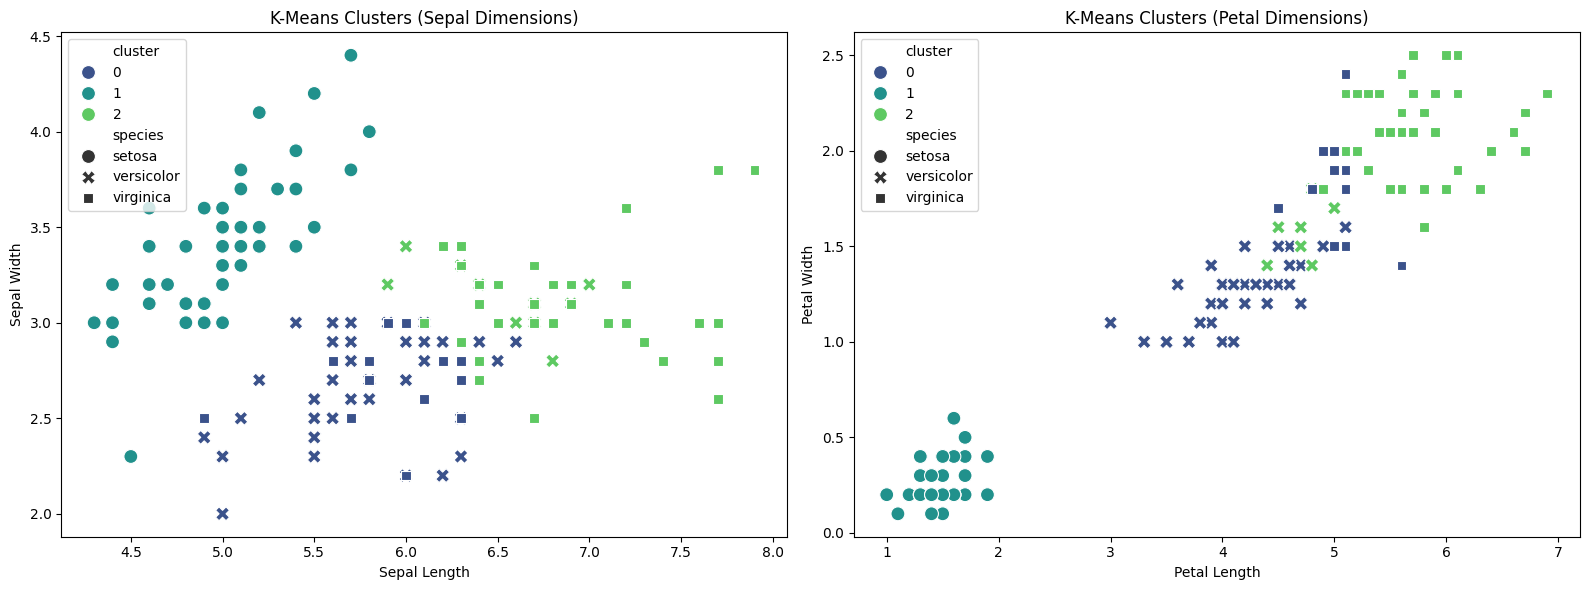

In [215]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the plotting environment with subplots to visualize Sepal and Petal attributes separately
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Sepal Dimensions Scatter Plot
sns.scatterplot(
    ax=axes[0],
    data=iris_clustered,
    x='sepal_length',
    y='sepal_width',
    hue='cluster',
    palette='viridis',
    style='species',
    s=100
)
axes[0].set_title('K-Means Clusters (Sepal Dimensions)')
axes[0].set_xlabel('Sepal Length')
axes[0].set_ylabel('Sepal Width')

# 2. Petal Dimensions Scatter Plot
sns.scatterplot(
    ax=axes[1],
    data=iris_clustered,
    x='petal_length',
    y='petal_width',
    hue='cluster',
    palette='viridis',
    style='species',
    s=100
)
axes[1].set_title('K-Means Clusters (Petal Dimensions)')
axes[1].set_xlabel('Petal Length')
axes[1].set_ylabel('Petal Width')

plt.tight_layout()
plt.show()

In [217]:
from sklearn.metrics import silhouette_score
score = silhouette_score(iris_scaler_clean, iris_labels)
print('Silhouette Score: %.3f' % score)

Silhouette Score: 0.461


In [219]:
from sklearn.metrics import davies_bouldin_score
score_db = davies_bouldin_score(iris_scaler_clean, iris_labels)
print('Davies-Bouldin Score: %.3f' % score_db)

Davies-Bouldin Score: 0.832


In [220]:
new_flower = pd.DataFrame({
    'sepal_length': [5.1],
    'sepal_width': [3.5],
    'petal_length': [1.4],
    'petal_width': [0.2]
})
new_flower

,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2


In [223]:
from sklearn.preprocessing import StandardScaler

# Instantiate and fit a scaler on our clean training features
scaler_obj = StandardScaler().fit(iris_features_clean)

# Transform the new flower sample using the fitted scaler
new_flower_scaled = scaler_obj.transform(new_flower)
new_flower_scaled

array([[-0.8980334 ,  1.01240113, -1.33325507, -1.30862368]])

In [225]:
# Predict the cluster label for the new scaled flower
predicted_cluster = kmeans_model.predict(new_flower_scaled)
print(f"Predicted Cluster for the new flower: {predicted_cluster[0]}")

Predicted Cluster for the new flower: 1
